# Praktikum 2 RKA Machine 

https://chat.deepseek.com/share/hw0pf6oxn1shb1j8pw

https://chat.deepseek.com/share/s9kxamm84dpx2qwnkz

Benedictus Ryu Gunawan - 5054251001

# Env Set Up

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path(os.getcwd()).parent
DATA = ROOT / "data"

print(f"Root Dir: {ROOT}")
print(f"Data Dir:{DATA}")

Root Dir: /home/ryz/data/collage/sem3/ml/github/praktikum/p2
Data Dir:/home/ryz/data/collage/sem3/ml/github/praktikum/p2/data


# Get Dataset

In [2]:
train_df = pd.read_csv(DATA / "train.csv")
test_df = pd.read_csv(DATA / "test.csv")
train_df.index = train_df["Student_ID"]
test_df.index = test_df["Student_ID"]
train_df.drop(columns=["Student_ID"], inplace=True)
test_df.drop(columns=["Student_ID"], inplace=True)
TARGET = "GPA_Change"
SEED = 3407

print(train_df.head(5)), print(test_df.head(5))


           Major_Category Year_of_Study  Pre_Semester_GPA  Weekly_GenAI_Hours  \
Student_ID                                                                      
103861               Arts        Senior             2.176                1.44   
119879         Humanities        Junior             2.458                5.14   
135634               STEM        Junior             3.323                0.14   
101039               STEM      Graduate             3.106               14.59   
110310         Humanities      Freshman             3.403                6.07   

                Primary_Use_Case Prompt_Engineering_Skill  Tool_Diversity  \
Student_ID                                                                  
103861      Copywriting/Drafting             Intermediate               2   
119879      Copywriting/Drafting                 Beginner               1   
135634       Summarizing_Reading                 Beginner               3   
101039                  Ideation               

(None, None)

In [3]:
train_df.info(), test_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4120 entries, 103861 to 113780
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Major_Category              3896 non-null   object 
 1   Year_of_Study               4120 non-null   object 
 2   Pre_Semester_GPA            4008 non-null   float64
 3   Weekly_GenAI_Hours          4120 non-null   float64
 4   Primary_Use_Case            3935 non-null   object 
 5   Prompt_Engineering_Skill    4120 non-null   object 
 6   Tool_Diversity              4120 non-null   int64  
 7   Paid_Subscription           4120 non-null   bool   
 8   Traditional_Study_Hours     3936 non-null   float64
 9   Perceived_AI_Dependency     4120 non-null   int64  
 10  Institutional_Policy        4120 non-null   object 
 11  Anxiety_Level_During_Exams  3911 non-null   float64
 12  Burnout_Risk_Level          4120 non-null   object 
 13  GPA_Change                  412

(None, None)

In [4]:
train_df.drop_duplicates(inplace=True)
test_df.drop_duplicates(inplace=True)

# EDA

## Missing Check

<Axes: >

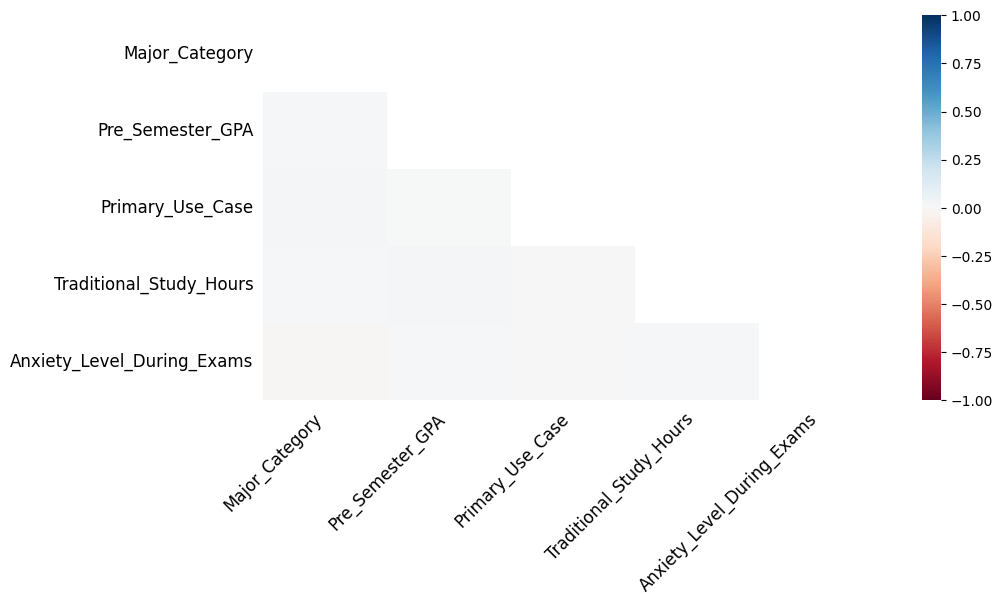

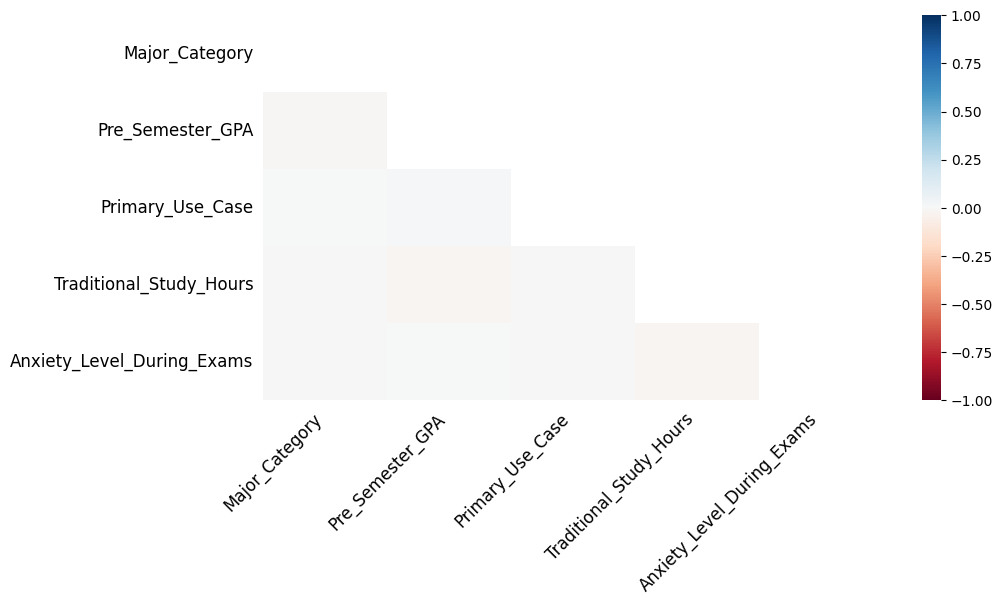

In [5]:
import missingno as msno

msno.heatmap(train_df, figsize=(10, 5), fontsize=12)
msno.heatmap(test_df, figsize=(10, 5), fontsize=12)

In [6]:
missing_cols_train = train_df.columns[train_df.isnull().any()].tolist()
missing_cols_test = test_df.columns[test_df.isnull().any()].tolist()
each_column_missing_train = train_df[missing_cols_train].isnull().sum()
each_column_missing_train_percent = train_df[missing_cols_train].isnull().mean() * 100


each_column_missing_test = test_df[missing_cols_test].isnull().sum()
each_column_missing_test_percent = test_df[missing_cols_test].isnull().mean() * 100


print("=== Missing Values in Train Data ===")
print(pd.DataFrame({
    "missing_count": each_column_missing_train,
    "missing_percent": each_column_missing_train_percent,
}))

print("\n=== Missing Values in Test Data ===")
print(pd.DataFrame({
    "missing_count": each_column_missing_test,
    "missing_percent": each_column_missing_test_percent,
}))

=== Missing Values in Train Data ===
                            missing_count  missing_percent
Major_Category                        213            5.325
Pre_Semester_GPA                      109            2.725
Primary_Use_Case                      182            4.550
Traditional_Study_Hours               178            4.450
Anxiety_Level_During_Exams            204            5.100

=== Missing Values in Test Data ===
                            missing_count  missing_percent
Major_Category                        514             5.14
Pre_Semester_GPA                      295             2.95
Primary_Use_Case                      380             3.80
Traditional_Study_Hours               375             3.75
Anxiety_Level_During_Exams            519             5.19


## Adversarial testing

In [7]:
# =========================================================
# Adversarial Validation — FIXED
# - Exclude TARGET (GPA_Change) karena hanya ada di train
# - Pakai intersection kolom supaya fair
# =========================================================
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier, Pool
import numpy as np
import pandas as pd

# Kolom fitur = yang ada di KEDUA sisi, exclude target & ID (ID sudah jadi index)
feat_cols = [c for c in train_df.columns if c in test_df.columns and c != TARGET]

adv = pd.concat(
    [train_df[feat_cols], test_df[feat_cols]],
    axis=0
).reset_index(drop=True)
adv["is_test"] = [0] * len(train_df) + [1] * len(test_df)

X_adv = adv[feat_cols].copy()
y_adv = adv["is_test"].values

# Encode kategorikal
cat_cols = X_adv.select_dtypes(include=["object", "bool"]).columns.tolist()
for c in cat_cols:
    X_adv[c] = X_adv[c].astype(str)
cat_idx = [X_adv.columns.get_loc(c) for c in cat_cols]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_adv = np.zeros(len(X_adv))
imp_adv = np.zeros(len(feat_cols))

for fold, (tr, va) in enumerate(skf.split(X_adv, y_adv)):
    tr_pool = Pool(X_adv.iloc[tr], y_adv[tr], cat_features=cat_idx)
    va_pool = Pool(X_adv.iloc[va], y_adv[va], cat_features=cat_idx)

    clf = CatBoostClassifier(
        iterations=2000,
        learning_rate=0.05,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=SEED + fold,
        early_stopping_rounds=100,
        verbose=False,
    )
    clf.fit(tr_pool, eval_set=va_pool, use_best_model=True)
    oof_adv[va] = clf.predict_proba(va_pool)[:, 1]
    imp_adv += clf.get_feature_importance(tr_pool) / skf.n_splits

adv_auc = roc_auc_score(y_adv, oof_adv)
print(f"Adversarial AUC (fixed): {adv_auc:.4f}")
print(f"n_features used        : {len(feat_cols)}")

imp_df = (
    pd.DataFrame({"feature": feat_cols, "importance": imp_adv})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
print(imp_df)

Adversarial AUC (fixed): 0.5897
n_features used        : 13
                       feature  importance
0           Weekly_GenAI_Hours   94.798659
1      Perceived_AI_Dependency    1.331925
2            Paid_Subscription    0.697355
3      Traditional_Study_Hours    0.697084
4             Pre_Semester_GPA    0.596753
5               Tool_Diversity    0.566482
6   Anxiety_Level_During_Exams    0.538652
7               Major_Category    0.200910
8           Burnout_Risk_Level    0.189665
9     Prompt_Engineering_Skill    0.184924
10        Institutional_Policy    0.093396
11            Primary_Use_Case    0.091167
12               Year_of_Study    0.013029


## CMP

In [8]:
num_cols = [c for c in feat_cols if c not in cat_cols]
cmp = pd.DataFrame({
    "train_mean": train_df[num_cols].mean(),
    "test_mean":  test_df[num_cols].mean(),
    "train_std":  train_df[num_cols].std(),
    "test_std":   test_df[num_cols].std(),
})
cmp["mean_diff_rel"] = (cmp["test_mean"] - cmp["train_mean"]).abs() / (cmp["train_mean"].abs() + 1e-9)
print(cmp.sort_values("mean_diff_rel", ascending=False))

                            train_mean  test_mean  train_std   test_std  \
Weekly_GenAI_Hours            5.867173  11.707154   5.166448  10.198419   
Perceived_AI_Dependency       3.163000   3.989500   1.532651   2.038040   
Anxiety_Level_During_Exams    4.262118   4.689062   4.014735   4.785453   
Traditional_Study_Hours      11.501065  10.850367   5.149392   5.185730   
Tool_Diversity                2.784000   2.797500   1.192979   1.189384   
Pre_Semester_GPA              3.153743   3.159112   0.546059   0.558929   

                            mean_diff_rel  
Weekly_GenAI_Hours               0.995366  
Perceived_AI_Dependency          0.261303  
Anxiety_Level_During_Exams       0.100172  
Traditional_Study_Hours          0.056577  
Tool_Diversity                   0.004849  
Pre_Semester_GPA                 0.001703  


## Type of Shift?

In [9]:
# Apakah ini location shift, scale shift, atau shape change?
qs = [0, .05, .25, .5, .75, .95, .99, 1]
q_df = pd.DataFrame({
    "train": train_df["Weekly_GenAI_Hours"].quantile(qs).values,
    "test":  test_df["Weekly_GenAI_Hours"].quantile(qs).values,
}, index=qs)
print(q_df)

# Apakah hubungannya dengan target monotonik? (penting untuk pilihan transform)
bins = np.quantile(train_df["Weekly_GenAI_Hours"], np.linspace(0, 1, 11))
tmp = train_df.copy()
tmp["_bin"] = pd.cut(tmp["Weekly_GenAI_Hours"], bins=bins, include_lowest=True)
print(
    tmp.groupby("_bin", observed=True)["GPA_Change"]
       .agg(["mean", "std", "count"])
       .reset_index()
)

        train     test
0.00   0.0000   0.0000
0.05   0.3595   0.5300
0.25   1.9575   3.2100
0.50   4.6000   8.4900
0.75   8.6725  18.2500
0.95  14.1805  32.7715
0.99  24.3202  40.0000
1.00  40.0000  40.0000
             _bin      mean       std  count
0  (-0.001, 0.75]  0.191661  0.171831    404
1    (0.75, 1.53]  0.194833  0.164232    400
2    (1.53, 2.41]  0.197535  0.170917    398
3   (2.41, 3.456]  0.204377  0.169397    398
4    (3.456, 4.6]  0.195810  0.164925    401
5    (4.6, 5.934]  0.223158  0.169913    399
6  (5.934, 7.713]  0.229985  0.168668    400
7  (7.713, 9.644]  0.232558  0.182904    400
8  (9.644, 12.49]  0.219960  0.175926    401
9   (12.49, 40.0]  0.220922  0.199068    399


## Quick EDA

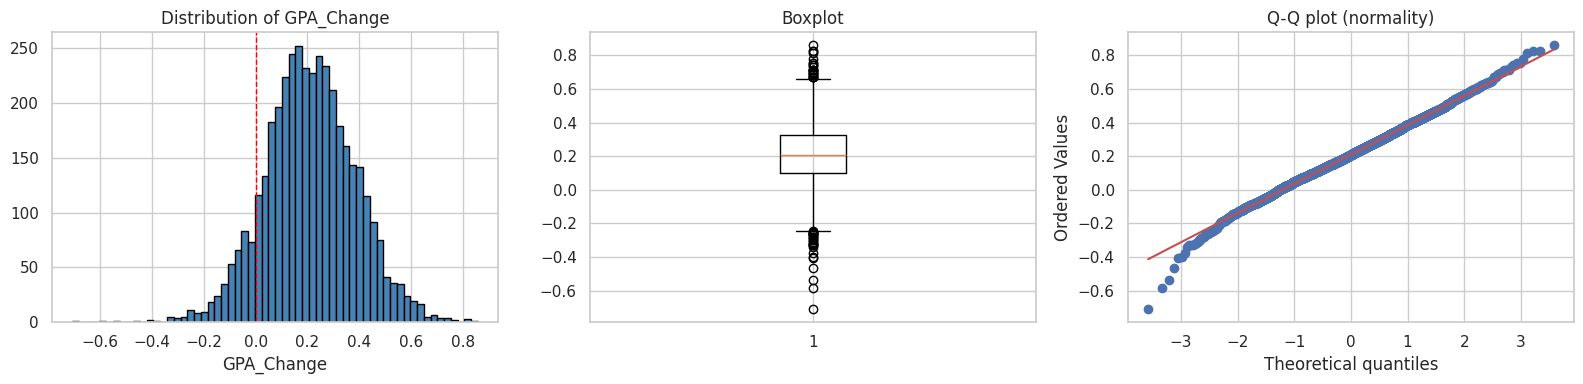

=== Target stats ===
count   4000.0000
mean       0.2111
std        0.1745
min       -0.7080
1%        -0.2100
5%        -0.0741
25%        0.0980
50%        0.2080
75%        0.3263
95%        0.4920
99%        0.6240
max        0.8590
Name: GPA_Change, dtype: float64
skew: -0.044, kurtosis: 0.528
% negative (GPA turun): 10.2%
% positive (GPA naik):  89.7%
% exactly 0:            0.0%

=== GPA_Change vs Pre_Semester_GPA ===
corr: -0.071
final_gpa min/max: 1.346 / 10.516
% out of [0,4]  : 0.47%

=== Pearson & Spearman correlation with target ===
                            pearson  spearman
Traditional_Study_Hours      0.3919    0.3839
Weekly_GenAI_Hours           0.0345    0.0680
Tool_Diversity               0.0613    0.0659
Perceived_AI_Dependency      0.0171    0.0309
Anxiety_Level_During_Exams   0.0235    0.0087
Pre_Semester_GPA            -0.0706   -0.0975


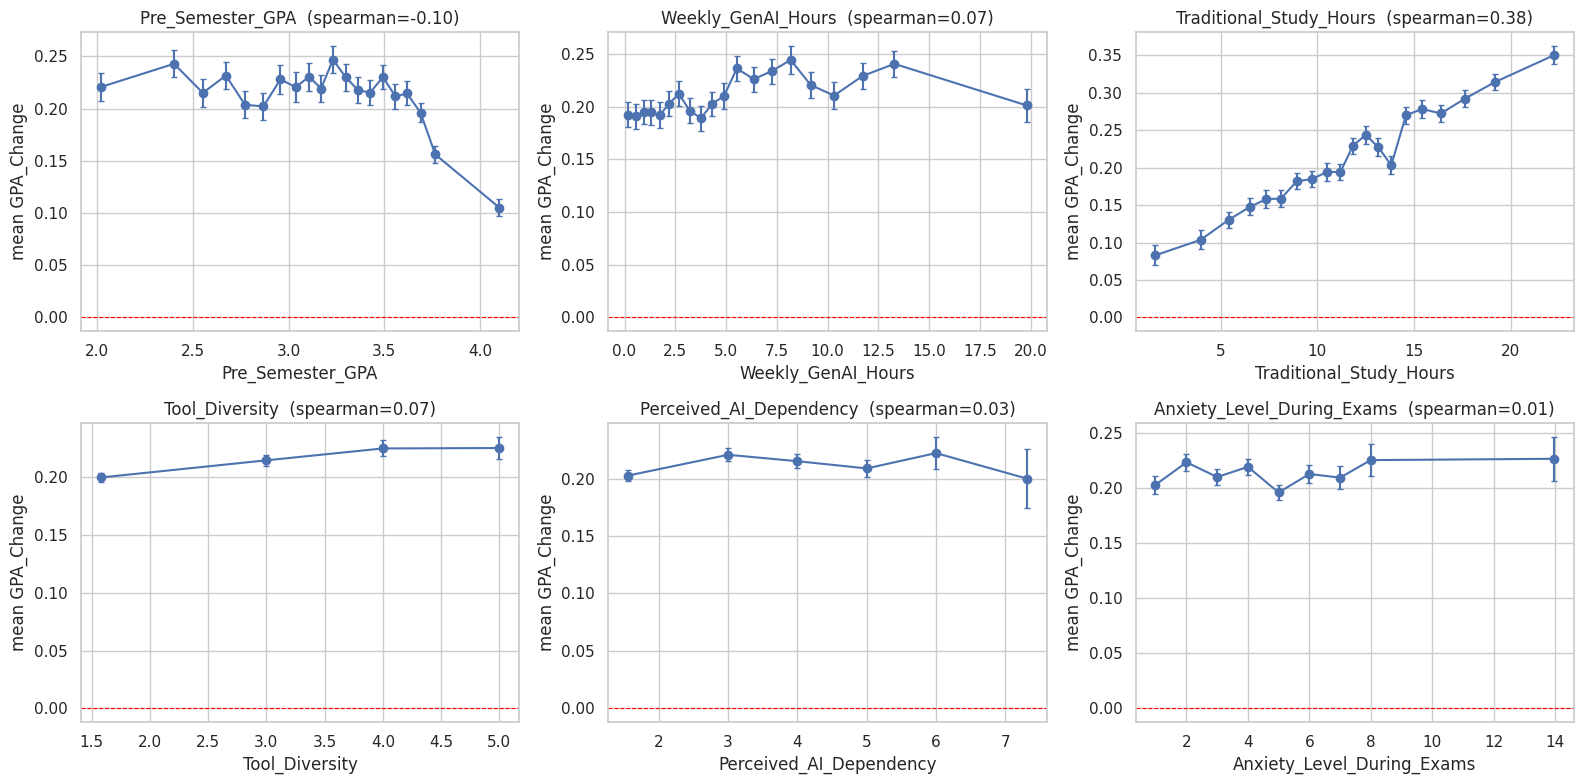


=== Categorical: mean target per level (+count) ===

--- Major_Category ---
                 mean    std  count
Major_Category                     
STEM           0.2326 0.1797   1059
Medical        0.2213 0.1680    503
Business       0.2041 0.1743    981
Arts           0.2040 0.1700    470
Humanities     0.1901 0.1718    774

--- Year_of_Study ---
                mean    std  count
Year_of_Study                     
Senior        0.2498 0.1544    860
Graduate      0.2482 0.1812    609
Junior        0.2296 0.1726    875
Sophomore     0.1931 0.1758    765
Freshman      0.1456 0.1682    891

--- Primary_Use_Case ---
                            mean    std  count
Primary_Use_Case                              
Debugging/Troubleshooting 0.2489 0.1842    916
Summarizing_Reading       0.2040 0.1621    668
Ideation                  0.2016 0.1719    827
Copywriting/Drafting      0.1966 0.1650    912
Direct_Answer_Generation  0.1957 0.1820    495

--- Prompt_Engineering_Skill ---
              

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# =========================================================
# 1. TARGET DISTRIBUTION
# =========================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(train_df[TARGET], bins=60, color="steelblue", edgecolor="black")
axes[0].axvline(0, color="red", ls="--", lw=1)
axes[0].set_title(f"Distribution of {TARGET}")
axes[0].set_xlabel(TARGET)

axes[1].boxplot(train_df[TARGET], vert=True)
axes[1].set_title("Boxplot")

from scipy import stats
stats.probplot(train_df[TARGET], plot=axes[2])
axes[2].set_title("Q-Q plot (normality)")
plt.tight_layout()
plt.show()

print("=== Target stats ===")
print(train_df[TARGET].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))
print(f"skew: {train_df[TARGET].skew():.3f}, kurtosis: {train_df[TARGET].kurt():.3f}")
print(f"% negative (GPA turun): {(train_df[TARGET] < 0).mean()*100:.1f}%")
print(f"% positive (GPA naik):  {(train_df[TARGET] > 0).mean()*100:.1f}%")
print(f"% exactly 0:            {(train_df[TARGET] == 0).mean()*100:.1f}%")

# Cek: apakah GPA_Change terikat dengan Pre_Semester_GPA? (target = final - pre)
print("\n=== GPA_Change vs Pre_Semester_GPA ===")
print(f"corr: {train_df[[TARGET, 'Pre_Semester_GPA']].corr().iloc[0,1]:.3f}")

# Cek: apakah nilai ekstrem membuat Pre_Semester_GPA + GPA_Change keluar [0,4]?
final_gpa = train_df["Pre_Semester_GPA"] + train_df[TARGET]
print(f"final_gpa min/max: {final_gpa.min():.3f} / {final_gpa.max():.3f}")
print(f"% out of [0,4]  : {((final_gpa < 0) | (final_gpa > 4)).mean()*100:.2f}%")

# =========================================================
# 2. NUMERIC FEATURES vs TARGET
# =========================================================
num_cols = [
    "Pre_Semester_GPA",
    "Weekly_GenAI_Hours",
    "Traditional_Study_Hours",
    "Tool_Diversity",
    "Perceived_AI_Dependency",
    "Anxiety_Level_During_Exams",
]
num_cols = [c for c in num_cols if c in train_df.columns]

print("\n=== Pearson & Spearman correlation with target ===")
corr_tbl = pd.DataFrame({
    "pearson":  [train_df[c].corr(train_df[TARGET]) for c in num_cols],
    "spearman": [train_df[c].corr(train_df[TARGET], method="spearman") for c in num_cols],
}, index=num_cols).sort_values("spearman", ascending=False)
print(corr_tbl)

# Scatter/LOESS-like: binned mean target per feature
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_cols):
    try:
        bins = pd.qcut(train_df[c], 20, duplicates="drop")
        m = train_df.groupby(bins, observed=True).agg(
            x=(c, "mean"),
            y=(TARGET, "mean"),
            yerr=(TARGET, "std"),
            n=(TARGET, "size"),
        ).reset_index(drop=True)
        ax.errorbar(m["x"], m["y"], yerr=m["yerr"]/np.sqrt(m["n"]),
                    marker="o", capsize=2)
        ax.set_title(f"{c}  (spearman={train_df[c].corr(train_df[TARGET], method='spearman'):.2f})")
        ax.set_xlabel(c); ax.set_ylabel("mean GPA_Change")
        ax.axhline(0, color="red", ls="--", lw=0.8)
    except Exception as e:
        ax.set_title(f"{c} (skipped: {e})")
plt.tight_layout()
plt.show()

# =========================================================
# 3. CATEGORICAL FEATURES vs TARGET
# =========================================================
cat_cols_eda = [
    "Major_Category",
    "Year_of_Study",
    "Primary_Use_Case",
    "Prompt_Engineering_Skill",
    "Paid_Subscription",
    "Institutional_Policy",
    "Burnout_Risk_Level",
]
cat_cols_eda = [c for c in cat_cols_eda if c in train_df.columns]

print("\n=== Categorical: mean target per level (+count) ===")
for c in cat_cols_eda:
    tbl = (
        train_df.groupby(c)[TARGET]
        .agg(["mean", "std", "count"])
        .sort_values("mean", ascending=False)
    )
    print(f"\n--- {c} ---")
    print(tbl)


## Categorical Check

In [11]:
# Deteksi otomatis kolom kategorikal
cat_cols_check = train_df.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

print(f"Kandidat kolom kategorikal ({len(cat_cols_check)}): {cat_cols_check}\n")

def audit_categorical(df, cols, name="train"):
    """Cek nilai unik + kotoran: leading/trailing space, casing, non-ascii, angka nyasar."""
    rows = []
    for c in cols:
        s = df[c]
        uniq = s.dropna().astype(str).unique()
        # Heuristik kotoran
        has_lead_trail_space = any(u != u.strip() for u in uniq)
        has_double_space     = any("  " in u for u in uniq)
        has_nonascii         = any(not u.isascii() for u in uniq)
        has_digit            = any(any(ch.isdigit() for ch in u) for u in uniq)
        # Casing inconsistency: lebih dari satu versi lowercase
        lower_map = {}
        for u in uniq:
            lower_map.setdefault(u.strip().lower(), set()).add(u)
        casing_inconsistent = any(len(v) > 1 for v in lower_map.values())

        rows.append({
            "column": c,
            "n_unique": s.nunique(dropna=True),
            "n_missing": int(s.isna().sum()),
            "n_unique_after_strip_lower": len(lower_map),
            "has_lead_trail_space": has_lead_trail_space,
            "has_double_space": has_double_space,
            "has_non_ascii": has_nonascii,
            "has_digit_in_value": has_digit,
            "casing_inconsistent": casing_inconsistent,
        })
    out = pd.DataFrame(rows)
    out.insert(0, "split", name)
    return out

audit_train = audit_categorical(train_df, cat_cols_check, "train")
audit_test  = audit_categorical(test_df,  cat_cols_check, "test")

print("=== AUDIT RINGKASAN ===")
print(pd.concat([audit_train, audit_test], ignore_index=True))

# Print nilai unik lengkap per kolom, dengan repr() supaya spasi/invisible char kelihatan
for c in cat_cols_check:
    print(f"\n=== {c} ===")
    tr_uniq = sorted(train_df[c].dropna().astype(str).unique())
    te_uniq = sorted(test_df[c].dropna().astype(str).unique())
    print(f"  train uniques ({len(tr_uniq)}):")
    for u in tr_uniq:
        print(f"    {repr(u)}")
    print(f"  test uniques ({len(te_uniq)}):")
    for u in te_uniq:
        print(f"    {repr(u)}")

# Cross-tab train vs test per kolom (count)
for c in cat_cols_check:
    print(f"\n=== Value counts: {c} ===")
    tr_vc = train_df[c].value_counts(dropna=False).rename("train_count")
    te_vc = test_df[c].value_counts(dropna=False).rename("test_count")
    combined = pd.concat([tr_vc, te_vc], axis=1).fillna(0).astype(int)
    combined["train_pct"] = (combined["train_count"] / len(train_df) * 100).round(2)
    combined["test_pct"]  = (combined["test_count"]  / len(test_df)  * 100).round(2)
    combined["pct_diff"]  = (combined["test_pct"] - combined["train_pct"]).round(2)
    print(combined)

Kandidat kolom kategorikal (7): ['Major_Category', 'Year_of_Study', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Paid_Subscription', 'Institutional_Policy', 'Burnout_Risk_Level']

=== AUDIT RINGKASAN ===
    split                    column  n_unique  n_missing  \
0   train            Major_Category         5        213   
1   train             Year_of_Study         5          0   
2   train          Primary_Use_Case         5        182   
3   train  Prompt_Engineering_Skill         3          0   
4   train         Paid_Subscription         2          0   
5   train      Institutional_Policy         3          0   
6   train        Burnout_Risk_Level         3          0   
7    test            Major_Category         5        514   
8    test             Year_of_Study         5          0   
9    test          Primary_Use_Case         5        380   
10   test  Prompt_Engineering_Skill         3          0   
11   test         Paid_Subscription         2          0   
12   test   

In [12]:
# =========================================================
# Cek: apakah setiap nilai unik di train ada di test, dan sebaliknya
# Kategori yang hanya ada di test -> model tidak akan kenal (risiko CatBoost
# fallback ke prior, atau unhandled kalau tidak native categorical)
# Kategori yang hanya ada di train -> model belajar sesuatu yang tidak dipakai
# =========================================================
compat_rows = []
for c in cat_cols_check:
    tr_set = set(train_df[c].dropna().astype(str).str.strip().str.lower())
    te_set = set(test_df[c].dropna().astype(str).str.strip().str.lower())

    only_train = tr_set - te_set
    only_test  = te_set - tr_set
    shared     = tr_set & te_set

    compat_rows.append({
        "column": c,
        "n_train_cats": len(tr_set),
        "n_test_cats":  len(te_set),
        "n_shared":     len(shared),
        "n_only_in_train": len(only_train),
        "n_only_in_test":  len(only_test),
        "only_in_train":   sorted(only_train),
        "only_in_test":    sorted(only_test),
    })

compat_df = pd.DataFrame(compat_rows)
print("=== TRAIN vs TEST category compatibility ===")
print(compat_df.drop(columns=["only_in_train", "only_in_test"]))

# Detail per kolom yang bermasalah
print("\n=== Detail kolom dengan kategori tidak cocok ===")
problematic = compat_df[(compat_df["n_only_in_train"] > 0) | (compat_df["n_only_in_test"] > 0)]
if len(problematic) == 0:
    print("✅ Semua nilai unik train ada di test dan sebaliknya.")
else:
    for _, row in problematic.iterrows():
        print(f"\n--- {row['column']} ---")
        if row["only_in_train"]:
            print(f"  Only in TRAIN (model belajar tapi tak muncul di test): {row['only_in_train']}")
        if row["only_in_test"]:
            print(f"  Only in TEST  (model tak pernah lihat ini!):        {row['only_in_test']}")

=== TRAIN vs TEST category compatibility ===
                     column  n_train_cats  n_test_cats  n_shared  \
0            Major_Category             5            5         5   
1             Year_of_Study             5            5         5   
2          Primary_Use_Case             5            5         5   
3  Prompt_Engineering_Skill             3            3         3   
4         Paid_Subscription             2            2         2   
5      Institutional_Policy             3            3         3   
6        Burnout_Risk_Level             3            3         3   

   n_only_in_train  n_only_in_test  
0                0               0  
1                0               0  
2                0               0  
3                0               0  
4                0               0  
5                0               0  
6                0               0  

=== Detail kolom dengan kategori tidak cocok ===
✅ Semua nilai unik train ada di test dan sebaliknya.


# Preprocessing

In [13]:
# =========================================================
# 1. PREPROCESSING v4 — kompak, log minimal
# =========================================================
NUMERIC_BOUNDS = {
    "Pre_Semester_GPA":           (0.0, 4.0),
    "Traditional_Study_Hours":    (0.0, 168.0),
    "Anxiety_Level_During_Exams": (1.0, 10.0),
    "Weekly_GenAI_Hours":         (0.0, 40.0),
    "Tool_Diversity":             (1.0, 5.0),
    "Perceived_AI_Dependency":    (1.0, 10.0),
}


def _fit_medians(df):
    out = {}
    for col, (lo, hi) in NUMERIC_BOUNDS.items():
        if col in df.columns:
            v = df[col][(~df[col].isna()) & df[col].between(lo, hi)]
            out[col] = float(v.median()) if len(v) else (lo + hi) / 2.0
    return out


def preprocess_and_fe(df, medians=None, is_train=True):
    df = df.copy()

    # --- fit or reuse medians ---
    if medians is None:
        medians = _fit_medians(df)

    # --- single pass: sentinel check + flag + impute ---
    n_inv = np.zeros(len(df), dtype=int)
    for col, (lo, hi) in NUMERIC_BOUNDS.items():
        if col not in df.columns:
            continue
        s = df[col]
        inv = s.isna() | ~s.between(lo, hi)
        df[f"{col}_is_missing"] = inv.astype(int)
        df[col] = s.where(~inv, medians[col])
        n_inv += inv.astype(int)

    for c in ["Major_Category", "Primary_Use_Case"]:
        if c in df.columns:
            n_inv += df[c].isna().astype(int)
            df[c] = df[c].fillna("Missing").astype(str)
    if "Paid_Subscription" in df.columns:
        n_inv += df["Paid_Subscription"].isna().astype(int)

    df["n_invalid_fields"] = n_inv

    # --- ordinal encoding ---
    for src, mp, out in [
        ("Year_of_Study",            {"Freshman":1,"Sophomore":2,"Junior":3,"Senior":4,"Graduate":5}, "Year_ord"),
        ("Prompt_Engineering_Skill", {"Beginner":0,"Intermediate":1,"Advanced":2},                     "Prompt_ord"),
        ("Burnout_Risk_Level",       {"Low":0,"Medium":1,"High":2},                                     "Burnout_ord"),
    ]:
        df[out] = df[src].map(mp).fillna(-1).astype(int)

    # --- Paid_Subscription robust ---
    ps = df["Paid_Subscription"]
    if ps.dtype == bool:
        df["Paid_Subscription_int"] = ps.astype(int)
    else:
        df["Paid_Subscription_int"] = (
            ps.astype(str).str.lower().str.strip()
            .map({"true":1,"false":0,"1":1,"0":0,"yes":1,"no":0})
            .fillna(-1).astype(int)
        )

    # --- feature engineering ---
    h, t = df["Weekly_GenAI_Hours"], df["Traditional_Study_Hours"]

    df["log_GenAI_Hours"] = np.log1p(h)
    df["log_Trad_Hours"]  = np.log1p(t)
    df["Total_Study_Hours"] = h + t
    df["AI_Study_Ratio"]    = h / (h + t + 1e-6)
    df["Trad_Study_Ratio"]  = t / (h + t + 1e-6)
    df["AI_per_Trad"]       = ((h + 1) / (t + 1)).clip(0, 100)
    df["AI_x_Dependency_per_hour"] = (df["Perceived_AI_Dependency"] / (h + 1)).clip(0, 10)
    df["Tools_per_AI_hour"]        = (df["Tool_Diversity"] / (h + 1)).clip(0, 5)
    df["AI_x_Tools"]               = h * df["Tool_Diversity"]
    df["Anxiety_x_Burnout"]        = df["Anxiety_Level_During_Exams"] * df["Burnout_ord"]
    df["Dependency_x_Anxiety"]     = df["Perceived_AI_Dependency"] * df["Anxiety_Level_During_Exams"]
    df["GPA_x_Total_Study"]        = df["Pre_Semester_GPA"] * df["Total_Study_Hours"]
    df["GPA_headroom_up"]          = 4.0 - df["Pre_Semester_GPA"]
    df["GPA_headroom_down"]        =       df["Pre_Semester_GPA"]
    df["GPA_bin"] = pd.cut(
        df["Pre_Semester_GPA"],
        bins=[-0.01, 1.0, 2.0, 2.5, 3.0, 3.5, 4.0],
        labels=False, include_lowest=True,
    ).astype(float)

    # --- one-line log ---
    tag = "TRAIN" if is_train else "TEST "
    inv_str = ", ".join(f"{c.replace('_is_missing','')}={int(df[c].sum())}"
                        for c in df.columns if c.endswith("_is_missing") and df[c].sum() > 0)
    print(f"  [{tag}] {len(df):5d} rows | n_invalid: {inv_str or 'none'}")

    return df, medians

In [14]:
# =========================================================
# CALL SITE — full pipeline
# =========================================================

# ---- 1. Split target & features ----
y_train_raw = train_df[TARGET].astype(float).values
train_df_fe = train_df.drop(columns=[TARGET]).copy()
test_df_fe  = test_df.copy()

print(f"Train: {train_df_fe.shape} | Test: {test_df_fe.shape}")

# ---- 2. Preprocess TRAIN (fit medians di sini) ----
print("\n=== Preprocessing TRAIN ===")
train_fe, medians = preprocess_and_fe(train_df_fe, is_train=True)

# ---- 3. Preprocess TEST (pakai medians train) ----
print("\n=== Preprocessing TEST ===")
test_fe, _ = preprocess_and_fe(test_df_fe, medians=medians, is_train=False)

# ---- 4. Align columns (robust: reindex, bukan indexing) ----
expected = train_fe.columns.tolist()

missing_in_test = [c for c in expected if c not in test_fe.columns]
extra_in_test   = [c for c in test_fe.columns if c not in expected]

if missing_in_test:
    print(f"  ⚠️  test_fe kehilangan kolom: {missing_in_test} → diisi NaN")
if extra_in_test:
    print(f"  ⚠️  test_fe punya kolom ekstra: {extra_in_test} → dibuang")

# Reindex memastikan kolom sama persis + urutan sama, tanpa error
test_fe = test_fe.reindex(columns=expected)

# ---- 5. Target physical clip ----
pre_gpa_train = train_fe["Pre_Semester_GPA"].values
gpa_end_raw   = pre_gpa_train + y_train_raw
gpa_end_clip  = np.clip(gpa_end_raw, 0.0, 4.0)
y_train       = gpa_end_clip - pre_gpa_train

n_changed = int((np.abs(y_train - y_train_raw) > 1e-9).sum())
print(f"\n[Target clip] {n_changed} baris di-clip "
      f"({100*n_changed/len(y_train):.2f}%)")
if n_changed:
    delta = np.abs(y_train - y_train_raw)
    print(f"  Max perubahan: {delta.max():.4f} | Mean: {delta[delta > 0].mean():.4f}")

# ---- 6. Sanity checks ----
# (a) Tidak ada NaN di kolom wajib
critical_cols = ["Pre_Semester_GPA", "Weekly_GenAI_Hours",
                 "Traditional_Study_Hours", "Anxiety_Level_During_Exams"]
for c in critical_cols:
    assert train_fe[c].notna().all(), f"NaN di train_fe[{c}]"
    assert test_fe[c].notna().all(),  f"NaN di test_fe[{c}]"

# (b) Pre_GPA di bound fisik
assert train_fe["Pre_Semester_GPA"].between(0, 4).all(), "Train Pre_GPA OOR!"
assert test_fe["Pre_Semester_GPA"].between(0, 4).all(),  "Test Pre_GPA OOR!"

# (c) GPA akhir di bound fisik (train target)
assert (pre_gpa_train + y_train).min() >= -1e-9, "GPA_akhir < 0 di train!"
assert (pre_gpa_train + y_train).max() <= 4 + 1e-9, "GPA_akhir > 4 di train!"

# (d) Bentuk data
assert len(train_fe) == len(y_train), "Panjang train_fe != y_train"

# ---- 7. Ringkasan ----
print(f"\n{'='*60}")
print(f"Shape — train: {train_fe.shape} | test: {test_fe.shape}")
print(f"y_train: mean={y_train.mean():.4f}, std={y_train.std():.4f}, "
      f"min={y_train.min():.4f}, max={y_train.max():.4f}")
print(f"Pre_GPA test: min={test_fe['Pre_Semester_GPA'].min():.4f}, "
      f"max={test_fe['Pre_Semester_GPA'].max():.4f}")
print(f"{'='*60}")

Train: (4000, 13) | Test: (10000, 13)

=== Preprocessing TRAIN ===
  [TRAIN]  4000 rows | n_invalid: Pre_Semester_GPA=128, Traditional_Study_Hours=178, Anxiety_Level_During_Exams=222

=== Preprocessing TEST ===
  [TEST ] 10000 rows | n_invalid: Pre_Semester_GPA=345, Traditional_Study_Hours=375, Anxiety_Level_During_Exams=569

[Target clip] 0 baris di-clip (0.00%)

Shape — train: (4000, 39) | test: (10000, 39)
y_train: mean=0.2111, std=0.1745, min=-0.7080, max=0.8590
Pre_GPA test: min=1.2920, max=3.9940


In [15]:
# =========================================================
# 2. TARGET PHYSICAL CLIP (jalankan setelah preprocess)
# =========================================================
y_train_raw = train_df[TARGET].copy()
pre_gpa    = train_fe["Pre_Semester_GPA"].values

gpa_end_raw     = pre_gpa + y_train_raw.values
gpa_end_clipped = np.clip(gpa_end_raw, 0.0, 4.0)
y_train_fixed   = gpa_end_clipped - pre_gpa

n_changed = (np.abs(y_train_fixed - y_train_raw.values) > 1e-6).sum()
print(f"Target di-clip: {n_changed} baris ({100*n_changed/len(y_train_raw):.2f}%)")
if n_changed:
    delta = np.abs(y_train_fixed - y_train_raw.values)
    print(f"  Max perubahan: {delta.max():.4f}, mean: {delta.mean():.4f}")

# Pakai y_train_fixed di seluruh pipeline ensemble
y_train = pd.Series(y_train_fixed, index=train_df.index)

Target di-clip: 0 baris (0.00%)


# Modelling

In [28]:
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.metrics import root_mean_squared_error, roc_auc_score
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor,
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from catboost import CatBoostRegressor, Pool, CatBoostClassifier
from lightgbm import LGBMRegressor
import lightgbm as lgb
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

SEED = 42
N_FOLDS = 5

# =========================================================
# 1. ADVERSARIAL WEIGHTS (plain normalization)
# =========================================================
X_adv = pd.concat([train_fe, test_fe], axis=0).reset_index(drop=True)
y_adv = np.array([0] * len(train_fe) + [1] * len(test_fe))

cat_features_adv = X_adv.select_dtypes(include=["object", "category"]).columns.tolist()
cat_idx_adv = [X_adv.columns.get_loc(c) for c in cat_features_adv]
X_adv_str = X_adv.copy()
for c in cat_features_adv:
    X_adv_str[c] = X_adv_str[c].astype(str)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_adv = np.zeros(len(X_adv_str))
for tr, va in skf.split(X_adv_str, y_adv):
    tr_pool = Pool(X_adv_str.iloc[tr], y_adv[tr], cat_features=cat_idx_adv)
    va_pool = Pool(X_adv_str.iloc[va], y_adv[va], cat_features=cat_idx_adv)
    clf = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6,
                             verbose=False, random_seed=SEED)
    clf.fit(tr_pool, eval_set=va_pool, use_best_model=True)
    oof_adv[va] = clf.predict_proba(va_pool)[:, 1]

adv_auc = roc_auc_score(y_adv, oof_adv)
print(f"Adversarial AUC: {adv_auc:.4f}")

if adv_auc < 0.55:
    print("  → Train≈Test. Bobot adversarial DIMATIKAN (uniform).")
    train_weights = np.ones(len(train_fe))
else:
    p = oof_adv[:len(train_fe)].copy()
    train_weights = p / p.mean()
    train_weights = np.clip(train_weights, 0.3, 3.0)

    n_eff = train_weights.sum()**2 / (train_weights**2).sum()
    n_floor = int((train_weights <= 0.3 + 1e-9).sum())
    n_ceil  = int((train_weights >= 3.0 - 1e-9).sum())
    print(f"  → Bobot AKTIF (plain). Range: [{train_weights.min():.3f}, "
          f"{train_weights.max():.3f}], mean={train_weights.mean():.3f}")
    print(f"     n_eff={n_eff:.0f}/{len(train_weights)} | floor={n_floor} | ceil={n_ceil}")

# =========================================================
# 2. DATA VARIANTS
# =========================================================
y = np.asarray(y_train).ravel()
N_TRAIN, N_TEST = len(train_fe), len(test_fe)

cat_features = train_fe.select_dtypes(include=["object", "category"]).columns.tolist()
cat_idx = [train_fe.columns.get_loc(c) for c in cat_features]
print(f"Categorical columns ({len(cat_features)}): {cat_features}")

# 2a. CatBoost: string
X_cat, X_test_cat = train_fe.copy(), test_fe.copy()
for c in cat_features:
    X_cat[c] = X_cat[c].astype(str)
    X_test_cat[c] = X_test_cat[c].astype(str)

# 2b. LightGBM: category
X_lgb, X_test_lgb = train_fe.copy(), test_fe.copy()
for c in cat_features:
    cats = sorted(set(train_fe[c].astype(str)) | set(test_fe[c].astype(str)))
    cdtype = pd.CategoricalDtype(categories=cats)
    X_lgb[c] = X_lgb[c].astype(str).astype(cdtype)
    X_test_lgb[c] = X_test_lgb[c].astype(str).astype(cdtype)

# 2c. XGBoost: category
X_xgb, X_test_xgb = train_fe.copy(), test_fe.copy()
for c in cat_features:
    cats = sorted(set(train_fe[c].astype(str)) | set(test_fe[c].astype(str)))
    cdtype = pd.CategoricalDtype(categories=cats)
    X_xgb[c] = X_xgb[c].astype(str).astype(cdtype)
    X_test_xgb[c] = X_test_xgb[c].astype(str).astype(cdtype)

# 2d. sklearn: one-hot
all_cats = pd.concat([train_fe[cat_features], test_fe[cat_features]], axis=0).astype(str)
dummies = pd.get_dummies(all_cats, drop_first=False, dtype=int)
X_num = pd.concat([
    train_fe.drop(columns=cat_features).reset_index(drop=True),
    dummies.iloc[:N_TRAIN].reset_index(drop=True),
], axis=1)
X_test_num = pd.concat([
    test_fe.drop(columns=cat_features).reset_index(drop=True),
    dummies.iloc[N_TRAIN:].reset_index(drop=True),
], axis=1)
X_test_num = X_test_num[X_num.columns]
print(f"X_num shape: {X_num.shape}")

DATA_MAP = {
    "cat": (X_cat, X_test_cat),
    "lgb": (X_lgb, X_test_lgb),
    "xgb": (X_xgb, X_test_xgb),
    "num": (X_num, X_test_num),
}

# =========================================================
# 3. DEFINISI 20 BASE MODEL
# =========================================================
def cat_base(seed):
    return CatBoostRegressor(iterations=2000, learning_rate=0.03, depth=6, l2_leaf_reg=5,
                             loss_function="RMSE", eval_metric="RMSE",
                             random_seed=seed, early_stopping_rounds=100, verbose=False)

def cat_deep(seed):
    return CatBoostRegressor(iterations=2000, learning_rate=0.02, depth=8, l2_leaf_reg=8,
                             loss_function="RMSE", eval_metric="RMSE",
                             random_seed=seed, early_stopping_rounds=100, verbose=False)

def cat_shallow(seed):
    return CatBoostRegressor(iterations=3000, learning_rate=0.05, depth=4, l2_leaf_reg=3,
                             loss_function="RMSE", eval_metric="RMSE",
                             random_seed=seed, early_stopping_rounds=100, verbose=False)

def lgb_base(seed):
    return LGBMRegressor(n_estimators=3000, learning_rate=0.03, num_leaves=63,
                         min_child_samples=20, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.8, reg_lambda=5,
                         random_state=seed, n_jobs=-1, verbose=-1)

def lgb_linear(seed):
    return LGBMRegressor(n_estimators=2000, learning_rate=0.03, num_leaves=31,
                         linear_tree=True, min_child_samples=30,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                         reg_lambda=10, random_state=seed, n_jobs=-1, verbose=-1)

def xgb_base(seed):
    return XGBRegressor(n_estimators=2000, learning_rate=0.03, max_depth=6,
                        subsample=0.8, colsample_bytree=0.8, reg_lambda=5,
                        enable_categorical=True, tree_method="hist",
                        random_state=seed, n_jobs=-1, verbosity=0,
                        early_stopping_rounds=100, eval_metric="rmse")

def xgb_deep(seed):
    return XGBRegressor(n_estimators=2500, learning_rate=0.02, max_depth=8,
                        subsample=0.7, colsample_bytree=0.7, reg_lambda=10, min_child_weight=5,
                        enable_categorical=True, tree_method="hist",
                        random_state=seed, n_jobs=-1, verbosity=0,
                        early_stopping_rounds=100, eval_metric="rmse")

def rf_base(seed):
    return RandomForestRegressor(n_estimators=500, min_samples_leaf=3, max_features=0.5,
                                 random_state=seed, n_jobs=-1)

def et_base(seed):
    return ExtraTreesRegressor(n_estimators=500, min_samples_leaf=3, max_features=0.5,
                               random_state=seed, n_jobs=-1)

def hgb_base(seed):
    return HistGradientBoostingRegressor(max_iter=2000, learning_rate=0.03, max_depth=6,
                                         l2_regularization=5, early_stopping=True,
                                         validation_fraction=0.1, random_state=seed)

def ridge_base(seed):
    return Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))])

def enet_base(seed):
    return Pipeline([("sc", StandardScaler()),
                     ("m", ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000, random_state=seed))])

MODEL_SPECS = [
    ("cat_base_s1",    "cat", cat_base,    101),
    ("cat_base_s2",    "cat", cat_base,    202),
    ("cat_deep_s1",    "cat", cat_deep,    101),
    ("cat_deep_s2",    "cat", cat_deep,    202),
    ("cat_shallow_s1", "cat", cat_shallow, 101),
    ("cat_shallow_s2", "cat", cat_shallow, 202),
    ("lgb_base_s1",    "lgb", lgb_base,    101),
    ("lgb_base_s2",    "lgb", lgb_base,    202),
    ("lgb_linear_s1",  "lgb", lgb_linear,  101),
    ("lgb_linear_s2",  "lgb", lgb_linear,  202),
    ("xgb_base_s1",    "xgb", xgb_base,    101),
    ("xgb_base_s2",    "xgb", xgb_base,    202),
    ("xgb_deep_s1",    "xgb", xgb_deep,    101),
    ("xgb_deep_s2",    "xgb", xgb_deep,    202),
    ("rf_s1",          "num", rf_base,     101),
    ("rf_s2",          "num", rf_base,     202),
    ("et_s1",          "num", et_base,     101),
    ("hgb_s1",         "num", hgb_base,    101),
    ("ridge",          "num", ridge_base,  42),
    ("enet",           "num", enet_base,   42),
]
assert len(MODEL_SPECS) == 20
print(f"\nTotal base models: {len(MODEL_SPECS)}")

# =========================================================
# 4. TRAIN SEMUA BASE MODEL
# =========================================================
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_indices = list(kf.split(X_cat, y))

oof_all, test_all, rmse_all = {}, {}, {}
print("\n=== Training 20 base models ===\n")

for name, variant, build_fn, seed in MODEL_SPECS:
    X_full, X_te = DATA_MAP[variant]
    oof = np.zeros(N_TRAIN)
    test_pred = np.zeros(N_TEST)
    t0 = time.time()

    for fold, (tr_idx, va_idx) in enumerate(fold_indices):
        X_tr = X_full.iloc[tr_idx]
        X_va = X_full.iloc[va_idx]
        y_tr, y_va = y[tr_idx], y[va_idx]
        w_tr = train_weights[tr_idx]

        m = build_fn(seed + fold)

        if variant == "cat":
            tr_pool = Pool(X_tr, y_tr, cat_features=cat_idx, weight=w_tr)
            va_pool = Pool(X_va, y_va, cat_features=cat_idx)
            m.fit(tr_pool, eval_set=va_pool, use_best_model=True)
            oof[va_idx] = m.predict(va_pool)
            test_pred += m.predict(Pool(X_te, cat_features=cat_idx)) / N_FOLDS

        elif variant == "lgb":
            m.fit(X_tr, y_tr, sample_weight=w_tr,
                  eval_set=[(X_va, y_va)],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
            oof[va_idx] = m.predict(X_va)
            test_pred += m.predict(X_te) / N_FOLDS

        elif variant == "xgb":
            m.fit(X_tr, y_tr, sample_weight=w_tr,
                  eval_set=[(X_va, y_va)], verbose=False)
            oof[va_idx] = m.predict(X_va)
            test_pred += m.predict(X_te) / N_FOLDS

        else:  # num
            if name in ("rf_s1", "rf_s2", "et_s1", "hgb_s1"):
                m.fit(X_tr, y_tr, sample_weight=w_tr)
            else:
                m.fit(X_tr, y_tr)
            oof[va_idx] = m.predict(X_va)
            test_pred += m.predict(X_te) / N_FOLDS

    oof_all[name] = oof
    test_all[name] = test_pred
    r = root_mean_squared_error(y, oof)
    rmse_all[name] = r
    print(f"  {name:18s} | OOF RMSE: {r:.5f} | {time.time()-t0:5.1f}s")

# =========================================================
# 5. STACKING — 3 VARIAN + BLEND
# =========================================================
model_names = [n for n, *_ in MODEL_SPECS]
oof_matrix = np.column_stack([oof_all[n] for n in model_names])
test_matrix = np.column_stack([test_all[n] for n in model_names])
print(f"\nOOF matrix shape: {oof_matrix.shape}")

meta_kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + 1)

def stack_ridge(oof_mat, test_mat, y, alpha=1.0):
    n_tr, n_te = len(oof_mat), len(test_mat)
    mo, mt = np.zeros(n_tr), np.zeros(n_te)
    for tr_idx, va_idx in meta_kf.split(oof_mat):
        m = Ridge(alpha=alpha)
        m.fit(oof_mat[tr_idx], y[tr_idx])
        mo[va_idx] = m.predict(oof_mat[va_idx])
        mt += m.predict(test_mat) / N_FOLDS
    return mo, mt

sorted_models = sorted(rmse_all.items(), key=lambda kv: kv[1])
best_single_name, best_single_rmse = sorted_models[0]

# (1) All 20 — plain Ridge
s1_oof, s1_test = stack_ridge(oof_matrix, test_matrix, y, alpha=1.0)

# (2) Mean all 20 (no learning)
s2_oof = oof_matrix.mean(axis=1)
s2_test = test_matrix.mean(axis=1)

# (3) Best single
s3_oof = oof_all[best_single_name]
s3_test = test_all[best_single_name]

variants = {
    "Ridge-20 (plain)": (s1_oof, s1_test, root_mean_squared_error(y, s1_oof)),
    "Mean-20":          (s2_oof, s2_test, root_mean_squared_error(y, s2_oof)),
    "Best single":      (s3_oof, s3_test, best_single_rmse),
}

# Blend Ridge-20 + BestSingle (50/50)
b_oof = 0.5 * s1_oof + 0.5 * s3_oof
b_test = 0.5 * s1_test + 0.5 * s3_test
variants["Blend: Ridge20 + BestSingle"] = (
    b_oof, b_test, root_mean_squared_error(y, b_oof)
)

print("\n=== Perbandingan Semua Varian ===")
print(f"{'Variant':40s} {'OOF RMSE':>10s}")
print("-" * 52)
for name, (_, _, r) in variants.items():
    print(f"{name:40s} {r:10.5f}")

final_name = min(variants, key=lambda k: variants[k][2])
final_oof, final_test, final_rmse = variants[final_name]
print(f"\n→ DIPILIH: {final_name} (OOF RMSE: {final_rmse:.5f})")

# =========================================================
# 6. DIAGNOSTIK
# =========================================================
print("\nKorelasi seed-pair:")
for a, b in [("cat_base_s1","cat_base_s2"), ("cat_deep_s1","cat_deep_s2"),
             ("lgb_base_s1","lgb_base_s2"), ("lgb_linear_s1","lgb_linear_s2"),
             ("xgb_base_s1","xgb_base_s2"), ("xgb_deep_s1","xgb_deep_s2"),
             ("rf_s1","rf_s2")]:
    c = np.corrcoef(oof_all[a], oof_all[b])[0, 1]
    flag = " ⚠️" if c > 0.9999 else " ✓"
    print(f"  {a:16s} vs {b:16s}: corr={c:.5f}{flag}")

# Bobot meta (always retrain pada all 20 untuk ditampilkan)
meta_full = Ridge(alpha=1.0).fit(oof_matrix, y)
imp = pd.Series(meta_full.coef_, index=model_names).sort_values(ascending=False)
print("\nTop-10 bobot meta-learner (Ridge-20):")
print(imp.head(10).to_string())

# =========================================================
# 7. CLIP & SUBMIT
# =========================================================
pre_gpa_test = test_fe["Pre_Semester_GPA"].values
assert pre_gpa_test.min() >= 0 and pre_gpa_test.max() <= 4, \
    "Pre_GPA tidak bersih! Jalankan preprocessing dulu."

final_pred = np.clip(final_test, -pre_gpa_test, 4 - pre_gpa_test)
gpa_end    = pre_gpa_test + final_pred
assert gpa_end.min() >= 0 and gpa_end.max() <= 4

print(f"\nFinal pred: mean={final_pred.mean():.3f}, std={final_pred.std():.3f}, "
      f"min={final_pred.min():.3f}, max={final_pred.max():.3f}")
print(f"Target    : mean={y.mean():.3f}, std={y.std():.3f}, "
      f"min={y.min():.3f}, max={y.max():.3f}")

sample_submission = pd.read_csv(DATA / "sample_submission.csv")
submission = sample_submission.copy()
submission[TARGET] = final_pred
out_name = f"submission_{final_name.replace(' ', '_').replace(':', '').replace('+', 'plus')}.csv"
submission.to_csv(out_name, index=False)
print(f"\n✅ Saved: {out_name}")

Adversarial AUC: 0.6572
  → Bobot AKTIF (plain). Range: [0.670, 1.522], mean=1.000
     n_eff=3965/4000 | floor=0 | ceil=0
Categorical columns (6): ['Major_Category', 'Year_of_Study', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Institutional_Policy', 'Burnout_Risk_Level']
X_num shape: (4000, 59)

Total base models: 20

=== Training 20 base models ===

  cat_base_s1        | OOF RMSE: 0.14445 |   9.6s
  cat_base_s2        | OOF RMSE: 0.14411 |  10.7s
  cat_deep_s1        | OOF RMSE: 0.14485 |  26.1s
  cat_deep_s2        | OOF RMSE: 0.14465 |  31.3s
  cat_shallow_s1     | OOF RMSE: 0.14416 |   5.0s
  cat_shallow_s2     | OOF RMSE: 0.14393 |   5.4s
  lgb_base_s1        | OOF RMSE: 0.14789 |  30.4s
  lgb_base_s2        | OOF RMSE: 0.14779 |  33.5s
  lgb_linear_s1      | OOF RMSE: 0.14704 |  18.8s
  lgb_linear_s2      | OOF RMSE: 0.14764 |  16.9s
  xgb_base_s1        | OOF RMSE: 0.14637 |  16.0s
  xgb_base_s2        | OOF RMSE: 0.14669 |  17.6s
  xgb_deep_s1        | OOF RMSE: 0.14763 